In [ ]:
#  Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data
df = pd.read_excel("/content/raw_battery_data (1).xlsx")  # Replace with your actual file name


In [ ]:
# Check the column names
df.head()

,Bill no,Day,Month,Year,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR)
0,1003,2,2,2024,Chetan Pawar,8.484811e+09,Amaron,40B20L,Vehicle,1,3900
1,1004,2,2,2024,Ravi Valagude,NaN,Exide,700R,Vehicle,1,6500
2,1008,6,2,2024,Vinod Dhavate,9.004355e+09,Exide,MLDIN50,Vehicle,1,5500
3,1009,7,2,2024,Pragan Sachin,9.970952e+09,Amaron,BH40B20L,Vehicle,1,4000
4,1010,7,2,2024,Raghunath Abuchorge,9.226575e+09,Exide,EKO60L,Vehicle,1,3800


In [ ]:
# check the missing values
df.isnull().sum()

,0
Bill no,0
Day,0
Month,0
Year,0
Customer Name,0
Contact Number,15
Battery Company,0
Battery SKU,1
Battery Type,0
Qty,0


In [ ]:
#  Step 1: Fill missing Contact Numbers based on previous records of the same customer
df["Contact Number"] = df.groupby("Customer Name")["Contact Number"].ffill()

#  Step 2: If any contact numbers are still missing, replace them with "NA"
df["Contact Number"].fillna("NA", inplace=True)

#  Step 3: Verify if all missing values are handled
missing_contacts = df["Contact Number"].isnull().sum()
print(f"\nMissing Contact Numbers After Cleaning: {missing_contacts}")




Missing Contact Numbers After Cleaning: 0


<ipython-input-377-d543889402c7>:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Contact Number"].fillna("NA", inplace=True)
<ipython-input-377-d543889402c7>:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'NA' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df["Contact Number"].fillna("NA", inplace=True)


In [ ]:
df.head()

,Bill no,Day,Month,Year,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR)
0,1003,2,2,2024,Chetan Pawar,8484811398.0,Amaron,40B20L,Vehicle,1,3900
1,1004,2,2,2024,Ravi Valagude,NA,Exide,700R,Vehicle,1,6500
2,1008,6,2,2024,Vinod Dhavate,9004354666.0,Exide,MLDIN50,Vehicle,1,5500
3,1009,7,2,2024,Pragan Sachin,9970952100.0,Amaron,BH40B20L,Vehicle,1,4000
4,1010,7,2,2024,Raghunath Abuchorge,9226574668.0,Exide,EKO60L,Vehicle,1,3800


In [ ]:
# check if there any missing values still exists
df.isna().sum()

,0
Bill no,0
Day,0
Month,0
Year,0
Customer Name,0
Contact Number,0
Battery Company,0
Battery SKU,1
Battery Type,0
Qty,0


In [ ]:
# Array of unique battery company name
df['Battery Company'].unique()

array(['Amaron', 'Exide', 'Prycal', 'Livfast', 'Zebronics', 'Autobat',
       'UPLUS', 'Luminious', 'Arco', 'Microtek', 'Uplus', 'arco',
       'sf sonic', 'elito', 'Tata', 'uplus', 'exide', 'microtek',
       'luminous', 'livfast'], dtype=object)

In [ ]:
# Remove spaces if present any
df["Battery Company"] = df["Battery Company"].str.strip()


In [ ]:
old_company = df['Battery Company'].unique()
old_company

array(['Amaron', 'Exide', 'Prycal', 'Livfast', 'Zebronics', 'Autobat',
       'UPLUS', 'Luminious', 'Arco', 'Microtek', 'Uplus', 'arco',
       'sf sonic', 'elito', 'Tata', 'uplus', 'exide', 'microtek',
       'luminous', 'livfast'], dtype=object)

In [ ]:
company_counts = pd.Series(old_company).value_counts()
company_counts.sum()

np.int64(20)

In [ ]:
# All the company name converted in upper case
df["Battery Company"] = df["Battery Company"].str.upper()

In [ ]:
new_company = df['Battery Company'].unique()
new_company

array(['AMARON', 'EXIDE', 'PRYCAL', 'LIVFAST', 'ZEBRONICS', 'AUTOBAT',
       'UPLUS', 'LUMINIOUS', 'ARCO', 'MICROTEK', 'SF SONIC', 'ELITO',
       'TATA', 'LUMINOUS'], dtype=object)

In [ ]:
category_column = "Battery Company"  # Isko apne actual column name ke hisaab se update karna agar zaroori ho

# Category names ko merge karne ke liye dictionary
category_mapping = {
    "LUMINIOUS":"LUMINIOUS",
    "LUMINOUS":"LUMINIOUS",
}

# Replace karo duplicate categories
df[category_column] = df[category_column].replace(category_mapping)

In [ ]:
# Check again if duplicate still exists
new_company = df['Battery Company'].unique()
new_company

array(['AMARON', 'EXIDE', 'PRYCAL', 'LIVFAST', 'ZEBRONICS', 'AUTOBAT',
       'UPLUS', 'LUMINIOUS', 'ARCO', 'MICROTEK', 'SF SONIC', 'ELITO',
       'TATA'], dtype=object)

In [ ]:
company_counts = pd.Series(new_company).value_counts()
company_counts.sum()

np.int64(13)

In [ ]:
# Array of unique battery and inverter SKUs with possible case variations and missing values.
df['Battery SKU'].unique()

array(['40B20L', '700R', 'MLDIN50', 'BH40B20L', 'EKO60L', 'MTRED45L',
       '12V1625', 'TT 225', 'ML38B20L', 'PN600L', 'Zeb-U735', 'EY34B19L',
       'ML40LBH', 'MLDIN44L', 'MLN55(ISS)', '12V90ZAH', 'Drive 100L',
       'ETZ5', 'PN700R', 'ETZ4', 'BL40B20L', 'MLDIN66', 'EKO32L',
       'Electric Car', '5LB', '12V180H', 'DIN60', '12XL2.5', 'PN400R',
       'ML75023LBH', '12V7Ah', 'IBRF5000', 'LFDZT6', 'XLTZ4', '12V1125',
       'BTX7R', 'MLDIN55R', '12V200AH', nan, 'MLDIN70', 'TT 150',
       'DTX2.5', 'PN900', 'PN500', 'MLDIN65', 'BTZ5L', 'BL700', '12V1025',
       '180AH', '12V100R', '12V1125AH', '160AH', 'BTZ7R', 'ETZ7', '225AH',
       '12V7.5AH', '12V225AH', 'EY700', 'BTZ9', '12V100AH', '12V12AH',
       '35AH', '12V150AH', 'XL5LB', 'XL9LB', 'EY80', 'DRIVE88L',
       '12V1050', 'BL160', 'XLTZ9', '12V7AH', 'MT45', '12V160AH',
       '12V90AH', 'DIN66', '24V1700', '12V7', '12V1100', 'BL150', 'BL250',
       'MLDIN60', 'MLDIN55', 'BL700R', '12V925', 'PN600R', 'BTZ4',
       '12V1060'

In [ ]:
# Remove spaces if present any
df["Battery SKU"] = df["Battery SKU"].str.strip()


In [ ]:
old_sku = df['Battery SKU'].unique()
old_sku

array(['40B20L', '700R', 'MLDIN50', 'BH40B20L', 'EKO60L', 'MTRED45L',
       '12V1625', 'TT 225', 'ML38B20L', 'PN600L', 'Zeb-U735', 'EY34B19L',
       'ML40LBH', 'MLDIN44L', 'MLN55(ISS)', '12V90ZAH', 'Drive 100L',
       'ETZ5', 'PN700R', 'ETZ4', 'BL40B20L', 'MLDIN66', 'EKO32L',
       'Electric Car', '5LB', '12V180H', 'DIN60', '12XL2.5', 'PN400R',
       'ML75023LBH', '12V7Ah', 'IBRF5000', 'LFDZT6', 'XLTZ4', '12V1125',
       'BTX7R', 'MLDIN55R', '12V200AH', nan, 'MLDIN70', 'TT 150',
       'DTX2.5', 'PN900', 'PN500', 'MLDIN65', 'BTZ5L', 'BL700', '12V1025',
       '180AH', '12V100R', '12V1125AH', '160AH', 'BTZ7R', 'ETZ7', '225AH',
       '12V7.5AH', '12V225AH', 'EY700', 'BTZ9', '12V100AH', '12V12AH',
       '35AH', '12V150AH', 'XL5LB', 'XL9LB', 'EY80', 'DRIVE88L',
       '12V1050', 'BL160', 'XLTZ9', '12V7AH', 'MT45', '12V160AH',
       '12V90AH', 'DIN66', '24V1700', '12V7', '12V1100', 'BL150', 'BL250',
       'MLDIN60', 'MLDIN55', 'BL700R', '12V925', 'PN600R', 'BTZ4',
       '12V1060'

In [ ]:
sku_counts = pd.Series(old_sku).value_counts()
sku_counts.sum()

np.int64(202)

In [ ]:
# All the sku converted in upper case
df["Battery SKU"] = df["Battery SKU"].str.upper()

In [ ]:
new_sku = df['Battery SKU'].unique()
new_sku

array(['40B20L', '700R', 'MLDIN50', 'BH40B20L', 'EKO60L', 'MTRED45L',
       '12V1625', 'TT 225', 'ML38B20L', 'PN600L', 'ZEB-U735', 'EY34B19L',
       'ML40LBH', 'MLDIN44L', 'MLN55(ISS)', '12V90ZAH', 'DRIVE 100L',
       'ETZ5', 'PN700R', 'ETZ4', 'BL40B20L', 'MLDIN66', 'EKO32L',
       'ELECTRIC CAR', '5LB', '12V180H', 'DIN60', '12XL2.5', 'PN400R',
       'ML75023LBH', '12V7AH', 'IBRF5000', 'LFDZT6', 'XLTZ4', '12V1125',
       'BTX7R', 'MLDIN55R', '12V200AH', nan, 'MLDIN70', 'TT 150',
       'DTX2.5', 'PN900', 'PN500', 'MLDIN65', 'BTZ5L', 'BL700', '12V1025',
       '180AH', '12V100R', '12V1125AH', '160AH', 'BTZ7R', 'ETZ7', '225AH',
       '12V7.5AH', '12V225AH', 'EY700', 'BTZ9', '12V100AH', '12V12AH',
       '35AH', '12V150AH', 'XL5LB', 'XL9LB', 'EY80', 'DRIVE88L',
       '12V1050', 'BL160', 'XLTZ9', 'MT45', '12V160AH', '12V90AH',
       'DIN66', '24V1700', '12V7', '12V1100', 'BL150', 'BL250', 'MLDIN60',
       'MLDIN55', 'BL700R', '12V925', 'PN600R', 'BTZ4', '12V1060',
       'ML45D21

In [ ]:
sku_counts = pd.Series(new_sku).value_counts()
sku_counts.sum()

np.int64(172)

In [ ]:
total_unique_skus = df["Battery SKU"].nunique()
print("Total Unique SKUs:", total_unique_skus)


Total Unique SKUs: 172


In [ ]:
# check the number of missing values in Battery SKU column
df["Battery SKU"].isna().sum()

np.int64(2)

In [ ]:
df['Battery SKU'].mode()

,Battery SKU
0,ML38B20L


In [ ]:
# Fill the null value with the most frequent value
df["Battery SKU"] = df["Battery SKU"].fillna(df["Battery SKU"].mode()[0])

In [ ]:
df['Battery SKU'].isnull().sum()

np.int64(0)

In [ ]:
# Unique of Battery type
df["Battery Type"].unique()

array(['Vehicle', 'Inverter Machine', 'Inverter', 'Lift', 'Lift Battery',
       'inverter', 'vehicle', 'Inverter machine'], dtype=object)

In [ ]:
df["Battery Type"].value_counts()

,count
Battery Type,
Vehicle,344
vehicle,62
Inverter Machine,60
Inverter,55
inverter,28
Inverter machine,3
Lift,2
Lift Battery,2


In [ ]:
category_column = "Battery Type"  # Isko apne actual column name ke hisaab se update karna agar zaroori ho

# Category names ko merge karne ke liye dictionary
category_mapping = {
    "vehicle":"Vehicle Battery",
    "Vehicle":"Vehicle Battery",
    "Inverter Machine":"Inverter Battery",
    "Inverter":"Inverter Battery",
    "inverter":"Inverter Battery",
    "Inverter machine":"Inverter Battery",
    "Lift":"Lift Battery",
}

# Replace karo duplicate categories
df[category_column] = df[category_column].replace(category_mapping)

In [ ]:
df["Battery Type"].value_counts()

,count
Battery Type,
Vehicle Battery,406
Inverter Battery,146
Lift Battery,4


In [ ]:
df.isna().sum()

,0
Bill no,0
Day,0
Month,0
Year,0
Customer Name,0
Contact Number,0
Battery Company,0
Battery SKU,0
Battery Type,0
Qty,0


In [ ]:
df.head()

,Bill no,Day,Month,Year,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR)
0,1003,2,2,2024,Chetan Pawar,8484811398.0,AMARON,40B20L,Vehicle Battery,1,3900
1,1004,2,2,2024,Ravi Valagude,NA,EXIDE,700R,Vehicle Battery,1,6500
2,1008,6,2,2024,Vinod Dhavate,9004354666.0,EXIDE,MLDIN50,Vehicle Battery,1,5500
3,1009,7,2,2024,Pragan Sachin,9970952100.0,AMARON,BH40B20L,Vehicle Battery,1,4000
4,1010,7,2,2024,Raghunath Abuchorge,9226574668.0,EXIDE,EKO60L,Vehicle Battery,1,3800


In [ ]:
df["Date"] = pd.to_datetime(df[['Year', 'Month', 'Day']]).dt.date


In [ ]:
df.head()

,Bill no,Day,Month,Year,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR),Date
0,1003,2,2,2024,Chetan Pawar,8484811398.0,AMARON,40B20L,Vehicle Battery,1,3900,2024-02-02
1,1004,2,2,2024,Ravi Valagude,NA,EXIDE,700R,Vehicle Battery,1,6500,2024-02-02
2,1008,6,2,2024,Vinod Dhavate,9004354666.0,EXIDE,MLDIN50,Vehicle Battery,1,5500,2024-02-06
3,1009,7,2,2024,Pragan Sachin,9970952100.0,AMARON,BH40B20L,Vehicle Battery,1,4000,2024-02-07
4,1010,7,2,2024,Raghunath Abuchorge,9226574668.0,EXIDE,EKO60L,Vehicle Battery,1,3800,2024-02-07


In [ ]:
#  Define the desired column order
column_order = ['Bill no','Day','Month','Year', 'Date', 'Customer Name', 'Contact Number',
                'Battery Company', 'Battery SKU', 'Battery Type',
                'Qty', 'Amount (INR)']

#  Reorder the DataFrame columns
df = df[column_order]

# Display the updated DataFrame
df.head()


,Bill no,Day,Month,Year,Date,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR)
0,1003,2,2,2024,2024-02-02,Chetan Pawar,8484811398.0,AMARON,40B20L,Vehicle Battery,1,3900
1,1004,2,2,2024,2024-02-02,Ravi Valagude,NA,EXIDE,700R,Vehicle Battery,1,6500
2,1008,6,2,2024,2024-02-06,Vinod Dhavate,9004354666.0,EXIDE,MLDIN50,Vehicle Battery,1,5500
3,1009,7,2,2024,2024-02-07,Pragan Sachin,9970952100.0,AMARON,BH40B20L,Vehicle Battery,1,4000
4,1010,7,2,2024,2024-02-07,Raghunath Abuchorge,9226574668.0,EXIDE,EKO60L,Vehicle Battery,1,3800


In [ ]:
df=df.drop("Day",axis=1)

In [ ]:
df=df.drop("Year",axis=1)

In [ ]:
df=df.drop("Month",axis=1)

In [ ]:
df.head()

,Bill no,Date,Customer Name,Contact Number,Battery Company,Battery SKU,Battery Type,Qty,Amount (INR)
0,1003,2024-02-02,Chetan Pawar,8484811398.0,AMARON,40B20L,Vehicle Battery,1,3900
1,1004,2024-02-02,Ravi Valagude,NA,EXIDE,700R,Vehicle Battery,1,6500
2,1008,2024-02-06,Vinod Dhavate,9004354666.0,EXIDE,MLDIN50,Vehicle Battery,1,5500
3,1009,2024-02-07,Pragan Sachin,9970952100.0,AMARON,BH40B20L,Vehicle Battery,1,4000
4,1010,2024-02-07,Raghunath Abuchorge,9226574668.0,EXIDE,EKO60L,Vehicle Battery,1,3800


In [ ]:
df.isnull().sum()

,0
Bill no,0
Date,0
Customer Name,0
Contact Number,0
Battery Company,0
Battery SKU,0
Battery Type,0
Qty,0
Amount (INR),0


In [ ]:
# df.to_excel("cleaned_battery_data.xlsx", index=False)
# print("Cleaned file saved as 'cleaned_battery_data.xlsx'!")

In [ ]:
# Statistics of the data
df.describe()

,Qty,Amount (INR)
count,556.000000,556.000000
mean,1.113309,5341.703237
std,0.501999,3556.684579
min,1.000000,800.000000
25%,1.000000,3000.000000
50%,1.000000,4350.000000
75%,1.000000,7000.000000
max,6.000000,21372.000000


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

df['Month'] = df['Date'].dt.to_period('M')

In [ ]:
df['Revenue'] = df['Qty'] * df['Amount (INR)']

In [ ]:
# 5. Top 10 Highest Revenue Products

top_revenue = df.groupby(['Battery Company', 'Battery SKU'])['Revenue'].sum().sort_values(ascending=False).head(10)
print("Top 10 Revenue Generating Products:")
print(top_revenue)


Top 10 Revenue Generating Products:
Battery Company  Battery SKU
EXIDE            ML38B20L       266925
LUMINIOUS        12V1050        156100
                 12V160AH       151900
PRYCAL           12V225AH       130920
LIVFAST          12V160AH       112200
EXIDE            12V12AH        111300
                 12V1625         66936
                 12V150AH        66500
LUMINIOUS        12V150AH        64190
EXIDE            12V200AH        63872
Name: Revenue, dtype: int64


In [ ]:
# 6. Top 10 Selling Products by Quantity

top_selling = df.groupby(['Battery Company', 'Battery SKU'])['Qty'].sum().sort_values(ascending=False).head(10)
print("Top 10 Selling Products:")
print(top_selling)

Top 10 Selling Products:
Battery Company  Battery SKU
EXIDE            ML38B20L       79
LUMINIOUS        12V1050        21
EXIDE            ETZ4           20
                 EY34B19L       17
                 ML40LBH        16
                 ETZ5           13
LUMINIOUS        12V160AH       12
LIVFAST          12V160AH       11
EXIDE            12V12AH        11
PRYCAL           12V225AH       11
Name: Qty, dtype: int64


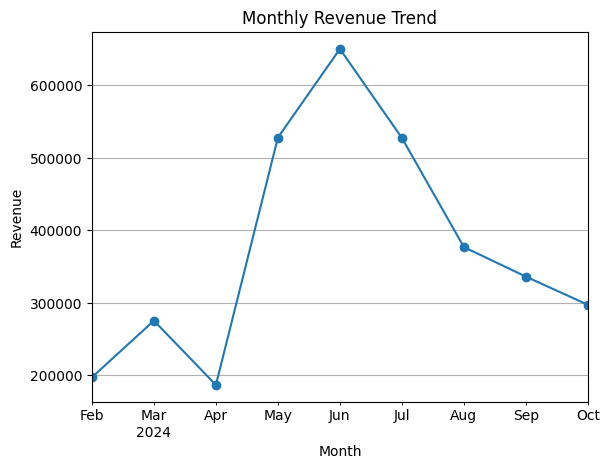

In [ ]:
# 7. Monthly Revenue Trend
monthly_revenue = df.groupby('Month')['Revenue'].sum()
monthly_revenue.plot(kind='line', marker='o', title='Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

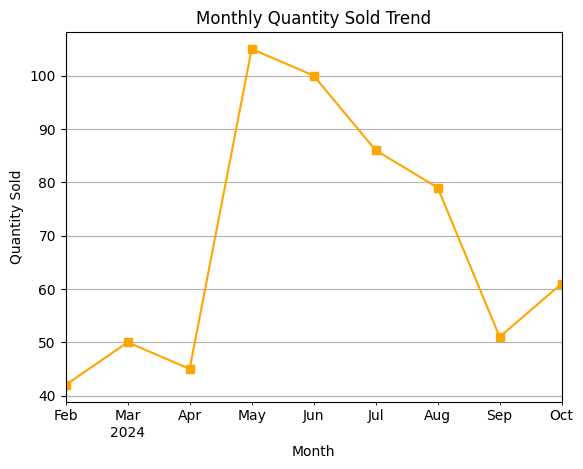

In [ ]:
# 8. Monthly Quantity Sold Trend
monthly_quantity = df.groupby('Month')['Qty'].sum()
monthly_quantity.plot(kind='line', marker='s', title='Monthly Quantity Sold Trend', color='orange')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')
plt.grid(True)
plt.show()